# 03 YouTube NBT spatial filtering

Filters the Finnish YouTube videos to those marked NBT-relevant by the Qwen3-14B classification, then intersects the geotagged videos with state-owned land / protected-area boundaries (Finland boundaries, state lands, nature reserves, national parks, wilderness areas).

**Inputs:**
- `data/videos_info_finland_all.csv` — Finnish YouTube video metadata
- `data/YouTube/preprocessing_data/nbt_identification_qwen3_14b.csv` — consolidated Qwen3-14B NBT Yes/No classification (`video_id`, `nbt_relevance`)
- `data/boundaries/` — Finland + protected-area / state-land geodata

**Outputs:**
- `data/YouTube/nbt_videos_in_state_owned_lands.gpkg` — geopackage of NBT-relevant videos intersected with state-owned lands

**Pipeline position:** step 03 of `scripts/YouTube/data_preprocessing/` (01 exploration → 02 NBT identification → 03 spatial filtering → 04 activity labeling (legacy))

# Import packages

In [1]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

import isodate
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import calendar
from pathlib import Path

# Read data

## Read nbt-related YouTube data

In [2]:
videos_info_finland = pd.read_csv('../../../data/YouTube/preprocessing_data/videos_info_finland_all.csv')
videos_info_finland_geotagged = videos_info_finland[~videos_info_finland['latitude'].isnull()]
print(f'videos_info_finland.shape: {videos_info_finland.shape}')
print(f'videos_info_finland_geotagged.shape: {videos_info_finland_geotagged.shape}')

/tmp/xuleyi11/ipykernel_2249447/2050454527.py:1: DtypeWarning: Columns (0: national_park, 1: region_code) have mixed types. Specify dtype option on import or set low_memory=False.
  videos_info_finland = pd.read_csv('../../../data/YouTube/preprocessing_data/videos_info_finland_all.csv')


videos_info_finland.shape: (198211, 34)
videos_info_finland_geotagged.shape: (191870, 34)


**Note (post-reorganization):** this notebook previously consolidated per-batch pickles `data/nbt_identification_files/nbt_identification_qwen3_14b_*.pkl` produced by `02_youtube_nbt_identification.py`. The batch pickle directory no longer exists; the consolidated result is now read directly from `data/YouTube/preprocessing_data/nbt_identification_qwen3_14b.csv`.

In [3]:
# Read the consolidated Qwen3-14B NBT relevance classification
# (formerly assembled from per-batch pkls; see note above)
nbt_identification = pd.read_csv('../../../data/YouTube/preprocessing_data/nbt_identification_qwen3_14b.csv')
nbt_identification.head()

,video_id,nbt_relevance
0,l4VWu7_rhfQ,No
1,qM_QA2CN9sI,Yes
2,R0Rl6_wRoaU,No
3,SxLz8sy07X8,No
4,7V6hRKOj7e8,No


In [4]:
# Get videos marked as 'Yes'
video_id_nbt_relevant = nbt_identification[nbt_identification['nbt_relevance']=='Yes'].video_id.to_list()
nbt_videos = videos_info_finland[videos_info_finland['video_id'].isin(video_id_nbt_relevant)].copy()

# Remove duplicates based on video_id
nbt_videos = nbt_videos.drop_duplicates(subset='video_id').reset_index(drop=True)

nbt_videos.shape

(33334, 34)

In [5]:
# Convert nbt_videos to GeoDataFrame
geometry = [Point(xy) for xy in zip(nbt_videos['longitude'], nbt_videos['latitude'])]

gdf_nbt_videos = gpd.GeoDataFrame(nbt_videos, geometry=geometry, crs='EPSG:4326')

gdf_nbt_videos = gdf_nbt_videos.to_crs(epsg=3067)

## Read boundaries

In [6]:
# Read Finland boundary shapefile
gdf_finland = gpd.read_file('../../../data/boundaries/Finland_shapefile/Finland_boundaries.shp')
gdf_finland.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [7]:
# Read state-owned lands boundary
gdf_state_lands = gpd.read_file('../../../data/boundaries/MH kiinteistot.gpkg')
gdf_state_lands.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

<Axes: >

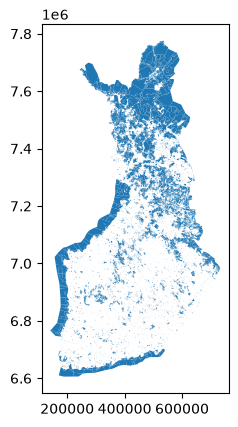

In [8]:
gdf_state_lands.plot()

In [9]:
# Read state-owned nature reserves boundary
gdf_state_nature_reserves = gpd.read_file('../../../data/boundaries/luonnonsuojelualueet_valtio/LsAlueValtio.shp')
gdf_state_nature_reserves.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [10]:
# Read national parks boundary
gdf_national_parks = gpd.read_file('../../../data/boundaries/finnish_national_parks_syke_2024.gpkg')
gdf_national_parks.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [11]:
# Read wilderness areas boundary
gdf_wilderness = gpd.read_file('../../../data/boundaries/luonnonsuojelualueet_eramaa/LsAlueEramaa.shp')
gdf_wilderness.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

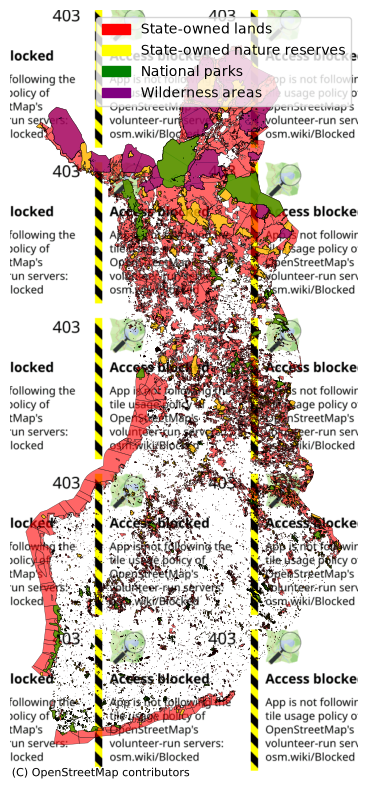

In [12]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import contextily as ctx

# Reproject to Web Mercator if needed
gdf_state_lands_web = gdf_state_lands.to_crs(epsg=3857)
gdf_state_nature_reserves_web = gdf_state_nature_reserves.to_crs(epsg=3857)
gdf_national_parks_web = gdf_national_parks.to_crs(epsg=3857)
gdf_wilderness_web = gdf_wilderness.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 10))

# Plot each layer
gdf_state_lands_web.plot(ax=ax, color='red', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)
gdf_state_nature_reserves_web.plot(ax=ax, color='yellow', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)
gdf_national_parks_web.plot(ax=ax, color='green', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)
gdf_wilderness_web.plot(ax=ax, color='purple', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)

# Add basemap
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=gdf_state_lands_web.crs, zorder=1)

# Create legend handles
red_patch = mpatches.Patch(color='red', label='State-owned lands')
yellow_patch = mpatches.Patch(color='yellow', label='State-owned nature reserves')
green_patch = mpatches.Patch(color='green', label='National parks')
purple_patch = mpatches.Patch(color='purple', label='Wilderness areas')

ax.legend(handles=[red_patch, yellow_patch, green_patch, purple_patch],
          loc='upper right',
          frameon=True)

# ax.set_title("State-Owned Lands, State-owned Nature Reserves, and National Parks")
ax.set_axis_off()

plt.show()



## Read nbt_related YouTube data within boundaries

In [13]:
def spatial_join_videos_with_boundary(gdf_videos, gdf_boundary):
    # Perform spatial join
    gdf_joined = gpd.sjoin(gdf_videos, gdf_boundary, how='inner', predicate='within')
    # Keep only original columns
    gdf_joined = gdf_joined[gdf_videos.columns]

    return gdf_joined

In [14]:
# Spatial join: keep only points that fall within state-owned lands
gdf_videos_state = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_state_lands)

# Spatial join: keep only points that fall within state-owned nature reserves
gdf_videos_nr = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_state_nature_reserves)
# Add a column "nature_reserve" to gdf_videos_state
gdf_videos_state['nature_reserve'] = gdf_videos_state['video_id'].isin(gdf_videos_nr['video_id']).astype(int)

# Spatial join: keep only points that fall within national parks
gdf_videos_np = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_national_parks)
# Add a column "national_park" to gdf_videos_state
gdf_videos_state['national_park'] = gdf_videos_state['video_id'].isin(gdf_videos_np['video_id']).astype(int)

# Spatial join: keep only points that fall within wilderness areas
gdf_videos_wa = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_wilderness)
# Add a column "wilderness_area" to gdf_videos_state
gdf_videos_state['wilderness_area'] = gdf_videos_state['video_id'].isin(gdf_videos_wa['video_id']).astype(int)

**Note (definition correction, 2026-10-21):** the `commercial_forest` flag was previously computed as
state-owned land *minus* nature reserves minus wilderness areas. That definition is wrong: Metsähallitus
state land also includes Luontopalvelut protected/recreation areas and Kiinteistökehitys properties.
The corrected definition (vetted against official SYKE/Metsähallitus documentation): a video is in a
commercial forest if its point intersects the Metsähallitus property polygons (`MH kiinteistot.gpkg`)
where `Admin_level == 'Metsätalous'` — the Forestry profit center, i.e. state multiple-use/commercial
forests. The other flags (`nature_reserve`, `national_park`, `wilderness_area`) are computed from
their own spatial joins and are unchanged.


In [15]:
area = 'state-owned lands'
gdf_videos = gdf_videos_state.copy()

# area = 'state-owned nature reserve'
# gdf_videos = gdf_videos[gdf_videos['nature_reserve']==1].copy()
gdf_videos_nr = gdf_videos[gdf_videos['nature_reserve']==1].copy()

# area = 'national park'
# gdf_videos = gdf_videos[gdf_videos['national_park']==1].copy()
gdf_videos_np = gdf_videos[gdf_videos['national_park']==1].copy()

# area = 'wilderness area'
# gdf_videos = gdf_videos[gdf_videos['wilderness_area']==1].copy()
gdf_videos_wa = gdf_videos[gdf_videos['wilderness_area']==1].copy()

# area = 'Metsähallitus forestry profit-center lands (Admin_level == "Metsätalous")'
# CORRECTED definition: commercial forest = video point within the Metsähallitus
# property polygons where Admin_level == 'Metsätalous' (Forestry profit center =
# state multiple-use/commercial forests). The old definition "state lands minus
# nature reserves minus wilderness areas" was wrong: state land also includes
# Luontopalvelut protected/recreation areas and Kiinteistökehitys properties.
gdf_forestry = gdf_state_lands[gdf_state_lands['Admin_level'] == 'Metsätalous'].copy()
gdf_videos_cf = spatial_join_videos_with_boundary(gdf_videos, gdf_forestry)
# Add a column "commercial_forest" to gdf_videos_state
gdf_videos_state['commercial_forest'] = gdf_videos_state['video_id'].isin(gdf_videos_cf['video_id']).astype(int)

In [16]:
print(f"Number of NBT videos in state-owned nature reserves: {gdf_videos_nr.shape[0]}")
print(f"Number of NBT videos in national parks: {gdf_videos_np.shape[0]}")
print(f"Number of NBT videos in wilderness areas: {gdf_videos_wa.shape[0]}")
print(f"Number of NBT videos in commercial forests (Admin_level == 'Metsätalous'): {gdf_videos_cf.shape[0]}")

Number of NBT videos in state-owned nature reserves: 2942
Number of NBT videos in national parks: 2678
Number of NBT videos in wilderness areas: 574
Number of NBT videos in commercial forests (Admin_level == 'Metsätalous'): 2389


In [17]:
def preprocess_gdf_videos(gdf_videos):
    # Drop duplicate video_id entries``
    gdf_videos = gdf_videos.drop_duplicates(subset='video_id').reset_index(drop=True)
    # Select relevant columns
    gdf_videos = gdf_videos[['video_id', 'title', 'description', 'channel_id', 'channel_title', 'published_at',
                             'location','category_id', 'topics', 'default_audio_language', 'default_language',
                             'tags', 'comment_count', 'like_count', 'view_count', 'thumbnail_default',
                             'duration', 'nature_reserve', 'national_park', 'wilderness_area', 'commercial_forest', 'geometry']]

    # Get the datetime
    gdf_videos['datetime'] = pd.to_datetime(gdf_videos['published_at'], utc=True)
    gdf_videos['year'] = gdf_videos['datetime'].dt.year
    gdf_videos['month'] = gdf_videos['datetime'].dt.month
    gdf_videos['year_month'] = gdf_videos['datetime'].dt.to_period('M')

    # Convert duration from ISO 8601 to seconds
    gdf_videos['duration_seconds'] = gdf_videos['duration'].apply(lambda x: isodate.parse_duration(x).total_seconds())

    return gdf_videos

In [18]:
# Preprocess gdf_videos_state
gdf_videos_state = preprocess_gdf_videos(gdf_videos_state)

# Join municipality (Kunta) boundaries so the output keeps the municipality / index_right columns
gdf_municipality = gpd.read_file('../../../data/boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg',
                                 layer='Kunta', engine='pyogrio')
gdf_municipality = gdf_municipality[['namefin', 'geometry']].to_crs(gdf_videos_state.crs)
gdf_videos_state = gpd.sjoin(gdf_videos_state, gdf_municipality, how='left', predicate='within')
gdf_videos_state = gdf_videos_state.rename(columns={'namefin': 'municipality'})

gdf_videos_state.to_file('../../../data/YouTube/nbt_videos_in_state_owned_lands.gpkg', driver='GPKG')

/tmp/xuleyi11/ipykernel_2249447/3502659221.py:14: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  gdf_videos['year_month'] = gdf_videos['datetime'].dt.to_period('M')


In [19]:
# Read the geopackage file of nbt_videos_in_state_owned_lands
gdf_videos_state = gpd.read_file('../../../data/YouTube/nbt_videos_in_state_owned_lands.gpkg')

In [20]:
gdf_videos_state.year.value_counts().sort_index()

year
2018     231
2019     413
2020    1102
2021    1420
2022    1269
2023    1895
Name: count, dtype: int64

## Clean channels and videos

Cleaning rules (carried over from the legacy `04_youtube_activity_labeling.ipynb`, which
used to produce the cleaned subset as a side effect):

1. **Landscape/drone channels** — channels with ≥5 videos containing "4k" or "drone" in
   title/description/tags are removed entirely; channels with <5 such videos are kept,
   plus 13 manually whitelisted channel IDs;
2. **Santa Claus channels** — videos from channels with "santa" in the channel title;
3. **Music videos** — videos whose YouTube topics contain music genres.

Writes `data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv` (the video-id list the
RQ notebooks filter the gpkg by).

In [21]:
# Cleaning rules (from the legacy 04 notebook)
df = gdf_videos_state.copy()

# 1. landscape/drone channels
ls_landscape_keywords = ['4k', 'drone']
pattern = '|'.join(ls_landscape_keywords)
mask = (df['title'].str.contains(pattern, case=False, na=False)
        | df['description'].str.contains(pattern, case=False, na=False)
        | df['tags'].str.contains(pattern, case=False, na=False))
df_landscape = df[mask]
channel_counts = df_landscape.groupby('channel_id').size()
ls_channels_landscape_to_keep = channel_counts[channel_counts < 5].index.tolist()
# channels manually identified as relevant to the research topic
ls_channels_landscape_to_keep.extend(['UC6G2cmWrqeAqyhy2reO72Xg', 'UC16NdAq6BIn7fy7sX2JTWzw', 'UCZ2GLsGoD9oqvBClzeseqKg', 'UCt529HCZxcbVtpvbNXsxUhA',
                                      'UCSNQ6urg5wx1VCtNjiyaxqA', 'UChBPAnbOE1bTbvEp-dttZXA', 'UCDH_XEf4KZeQflV8DBzXWAw', 'UC9Au1qH3EhKjX31pYKlfz4A', 'UCcEyJ3LOAHTEYCk2s3l7ydQ',
                                      'UC9Q0cWgt_Oa0pM_m_bchLjw', 'UCP_hsjEKYt9P2SwFUeOWlZg', 'UCrJygwIZvCQXOgYrwNlkqxA'])
ls_channels_landscape_to_remove = list(set(df_landscape['channel_id'].unique()) - set(ls_channels_landscape_to_keep))
ls_video_ids_landscape = df[df['channel_id'].isin(ls_channels_landscape_to_remove)]['video_id'].tolist()

# 2. Santa Claus channels
ls_video_ids_santa = df[df['channel_title'].str.contains('santa', case=False, na=False)]['video_id'].tolist()

# 3. music topics
ls_music_keywords = ['electronic_music', 'rock_music', 'christian_music', 'Classical_music', 'pop_music', 'independent_music']
mask_music = df['topics'].str.contains('|'.join(ls_music_keywords), case=False, na=False)
ls_video_ids_music = df[mask_music]['video_id'].tolist()

ls_video_ids_to_remove = list(set(ls_video_ids_landscape) | set(ls_video_ids_santa) | set(ls_video_ids_music))
df_cleaned = df[~df['video_id'].isin(ls_video_ids_to_remove)]
print(f"videos removed: {len(ls_video_ids_to_remove)} | cleaned: {df_cleaned.shape[0]}")

videos removed: 220 | cleaned: 6110


In [22]:
df_cleaned[['video_id', 'title', 'description', 'channel_id', 'channel_title', 'category_id',
            'topics', 'tags', 'duration', 'published_at', 'location']].to_csv(
    '../../../data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv', index=False)

# Also refresh the metadata CSV export (same 11-column schema, no geometry)
gdf_videos_state.drop(columns='geometry')[
    ['video_id', 'title', 'description', 'channel_id', 'channel_title', 'category_id',
     'topics', 'tags', 'duration', 'published_at', 'location']
].to_csv('../../../data/YouTube/nbt_videos_in_state_owned_lands.csv', index=False)